In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

In [2]:
# Example of reading a binary file containing interleaved I/Q samples
# raw = np.fromfile("IQ_2024-04-20T22-31-00_982199936.bin", dtype=np.int32)
raw = np.fromfile("IQ_2024-04-20T22-31-04_420048114.bin", dtype=np.int32)
iq = raw[0::2].astype(np.float64) + 1j * raw[1::2]  # (1_300_000,) complex, raw ADC units

In [3]:
FS = 1_300_000
DURATION = 1.0
N = int(FS * DURATION)
t = np.arange(N) / FS

def gate_window(num_samples: int, start: int, end: int) -> np.ndarray:
    g = np.zeros(num_samples, dtype=float)
    start = max(0, start)
    end = min(num_samples, end)
    if end > start:
        g[start:end] = 1.0
    return g


def plot_time_and_spectrogram(x: np.ndarray, fs: float, title: str, nperseg: int = 3200, noverlap: int = 2390, show_start: int = 0):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    show_start = max(0, min(show_start, len(x) - 1))
    idx = np.arange(show_start, min(show_start + 20_000, len(x)))
    axes[0].plot(idx, np.real(x[idx]), label="I")
    axes[0].plot(idx, np.imag(x[idx]), label="Q", alpha=0.8)
    axes[0].set_title(f"{title} (time-domain preview)")
    axes[0].set_xlabel("Sample index")
    axes[0].set_ylabel("Amplitude")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    f, tt, sxx = spectrogram(
        x,
        fs=fs,
        nperseg=nperseg,
        noverlap=noverlap,
        return_onesided=False,
        mode="magnitude",
        scaling="spectrum",
    )
    sxx = np.fft.fftshift(sxx, axes=0)
    f = np.fft.fftshift(f)

    im = axes[1].imshow(
        20 * np.log10(np.maximum(sxx, 1e-12)),
        aspect="auto",
        origin="lower",
        extent=[tt[0], tt[-1], f[0] / 1e3, f[-1] / 1e3],
        cmap="viridis",
    )
    axes[1].set_title(f"{title} (spectrogram)")
    axes[1].set_xlabel("Time [s]")
    axes[1].set_ylabel("Frequency [kHz]")
    fig.colorbar(im, ax=axes[1], label="Magnitude [dB]")
    plt.tight_layout()
    plt.show()

def tone_anomaly(fs=FS, duration=DURATION, f0=0.0, start=300_000, end=900_000):
    assert abs(f0) < fs / 2, f"f0={f0} is outside the Nyquist band (+/-{fs/2}), it would alias"
    n = int(fs * duration)
    tt = np.arange(n) / fs
    g = gate_window(n, start, end)
    return g * np.exp(1j * 2 * np.pi * f0 * tt)



In [4]:
tone = tone_anomaly(
    fs=FS,
    duration=len(iq) / FS,
    f0=300e3,  # must be within +/-FS/2 = +/-650 kHz (complex sampling)
    start=200_000,
    end=600_000
)

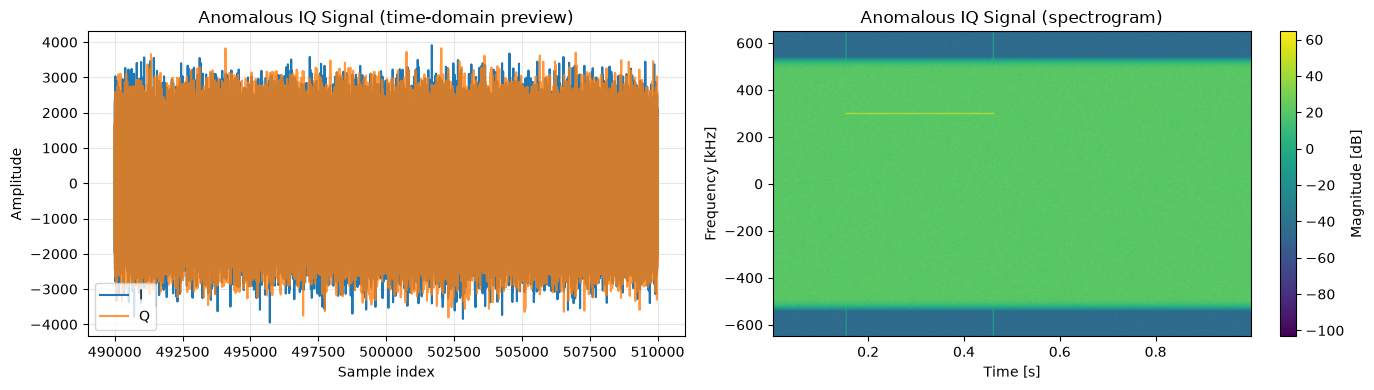

In [5]:
snr_db = 10  # tone power relative to the average power of the recording
p_noise = np.mean(np.abs(iq) ** 2)
amplitude = np.sqrt(p_noise * 10 ** (snr_db / 10))
anomalous_iq = iq + amplitude * tone
plot_time_and_spectrogram(anomalous_iq, fs=FS, title="Anomalous IQ Signal", show_start=490_000)